# Notebook 12 — Inference & Evaluation Plots

This notebook runs predictions on the test dataset (2024-2025) using the best trained model, maps predictions back to estates and months, and exports evaluation charts (Actual vs. Predicted, Feature Importance).

## 1. Import Packages & Local Configuration

In [1]:
import sys
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from pathlib import Path

# Ensure project root is in the path
sys.path.append(str(Path(os.getcwd()).parent))

import config
print("Outputs Folder:", config.OUTPUTS_DIR)

Outputs Folder: D:\A1\coco\Coconut_Yield_Prediction\outputs


## 2. Load Model, Scaler, and Test Feature Set

In [2]:
best_model = joblib.load(config.MODELS_DIR / "best_model.joblib")
scaler = joblib.load(config.MODELS_DIR / "scaler.joblib")

X_test = pd.read_csv(config.PROCESSED_DIR / "X_test.csv")
y_test_vals = pd.read_csv(config.PROCESSED_DIR / "y_test.csv").values.ravel()

# Scale features
non_binary_cols = [col for col in X_test.columns if not X_test[col].isin([0, 1]).all()]
X_test_scaled = X_test.copy()
X_test_scaled[non_binary_cols] = scaler.transform(X_test[non_binary_cols])

print("Loaded model:", type(best_model))
print("X_test shape:", X_test.shape)

Loaded model: <class 'xgboost.sklearn.XGBRegressor'>
X_test shape: (128, 39)


## 3. Predict Nuts per Palm

In [3]:
# Load full master feature dataset to align indices
df_master = pd.read_csv(config.PROCESSED_DIR / "master_features.csv")
test_meta = df_master[df_master["Year"] > 2023][["District", "Year", "Month", "Avg_Nuts_Palm"]].copy()

# Make predictions
test_meta["Predicted_Avg_Nuts_Palm"] = best_model.predict(X_test_scaled)

# Prevent negative predicted yields
test_meta["Predicted_Avg_Nuts_Palm"] = test_meta["Predicted_Avg_Nuts_Palm"].clip(lower=0.0)

# Save predictions
pred_out_path = config.OUTPUTS_DIR / "predictions.csv"
test_meta.to_csv(pred_out_path, index=False)
print(f"[SUCCESS] Saved test set predictions to {pred_out_path.name}")
print(test_meta.head(10))

[SUCCESS] Saved test set predictions to predictions.csv
      District  Year  Month  Avg_Nuts_Palm  Predicted_Avg_Nuts_Palm
60  Henwalawwa  2024      1           2.65                 3.561113
61  Henwalawwa  2024      2           2.50                 3.559290
62  Henwalawwa  2024      3           2.95                 3.662024
63  Henwalawwa  2024      4           3.50                 6.021437
64  Henwalawwa  2024      5           3.75                 5.614059
65  Henwalawwa  2024      6           5.40                 8.552910
66  Henwalawwa  2024      7           4.50                 5.382509
67  Henwalawwa  2024      8           7.60                 7.096500
68  Henwalawwa  2024      9           4.15                 3.911423
69  Henwalawwa  2024     10           3.65                 3.956729


## 4. Actual vs. Predicted Visualizations

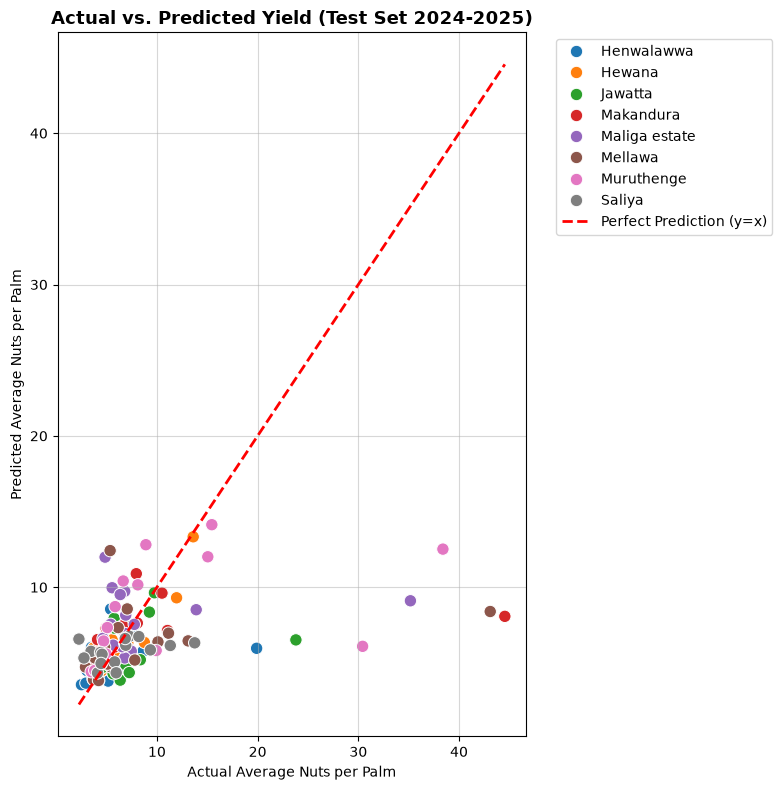

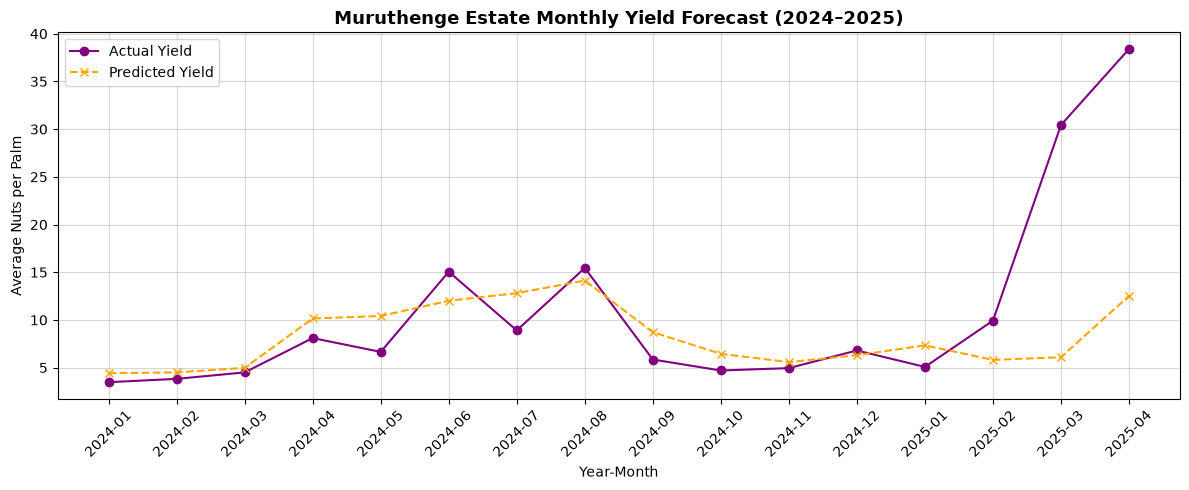

In [4]:
# Plot Actual vs Predicted
plt.figure(figsize=(8, 8))
sns.scatterplot(data=test_meta, x="Avg_Nuts_Palm", y="Predicted_Avg_Nuts_Palm", hue="District", s=80, palette="tab10")

max_val = max(test_meta["Avg_Nuts_Palm"].max(), test_meta["Predicted_Avg_Nuts_Palm"].max())
min_val = min(test_meta["Avg_Nuts_Palm"].min(), test_meta["Predicted_Avg_Nuts_Palm"].min())
plt.plot([min_val, max_val], [min_val, max_val], 'r--', linewidth=2, label="Perfect Prediction (y=x)")

plt.title("Actual vs. Predicted Yield (Test Set 2024-2025)", fontsize=13, fontweight='bold')
plt.xlabel("Actual Average Nuts per Palm")
plt.ylabel("Predicted Average Nuts per Palm")
plt.grid(True, alpha=0.5)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.savefig(config.FIGURES_DIR / "actual_vs_predicted_yield.png", dpi=300)
plt.show()

# Trend line over time for Muruthenge
m_df = test_meta[test_meta["District"] == "Muruthenge"].sort_values(by=["Year", "Month"])
m_df["Date"] = m_df["Year"].astype(str) + "-" + m_df["Month"].astype(str).str.zfill(2)

plt.figure(figsize=(12, 5))
plt.plot(m_df["Date"], m_df["Avg_Nuts_Palm"], 'purple', marker='o', label="Actual Yield")
plt.plot(m_df["Date"], m_df["Predicted_Avg_Nuts_Palm"], 'orange', marker='x', linestyle='--', label="Predicted Yield")
plt.title("Muruthenge Estate Monthly Yield Forecast (2024–2025)", fontsize=13, fontweight='bold')
plt.xlabel("Year-Month")
plt.ylabel("Average Nuts per Palm")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.5)
plt.legend()
plt.tight_layout()
plt.savefig(config.FIGURES_DIR / "muruthenge_forecast_comparison.png", dpi=300)
plt.show()

## 5. Feature Importance Chart

C:\Users\DELL\AppData\Local\Temp\ipykernel_9280\811982269.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_imp, x="Importance", y="Feature", palette="viridis")


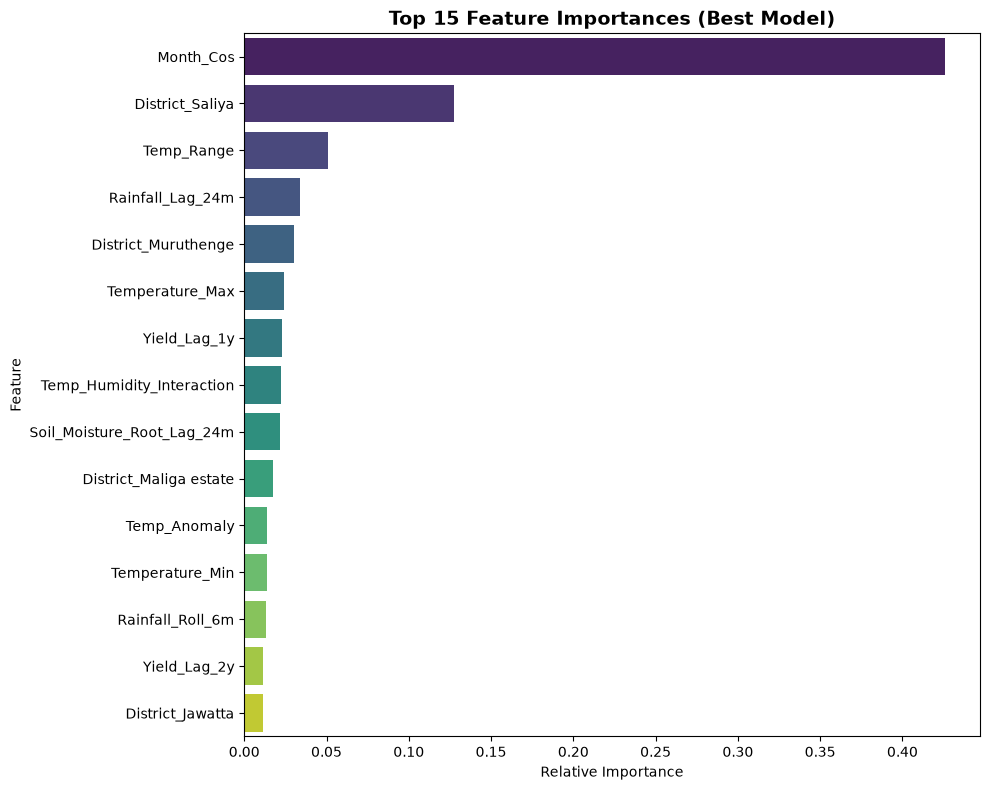

In [5]:
if hasattr(best_model, "feature_importances_"):
    importances = best_model.feature_importances_
    features = X_test.columns
    
    df_imp = pd.DataFrame({
        "Feature": features,
        "Importance": importances
    }).sort_values(by="Importance", ascending=False).head(15)
    
    plt.figure(figsize=(10, 8))
    sns.barplot(data=df_imp, x="Importance", y="Feature", palette="viridis")
    plt.title("Top 15 Feature Importances (Best Model)", fontsize=14, fontweight='bold')
    plt.xlabel("Relative Importance")
    plt.ylabel("Feature")
    plt.tight_layout()
    plt.savefig(config.FIGURES_DIR / "feature_importances.png", dpi=300)
    plt.show()
else:
    if hasattr(best_model, "coef_"):
        coefs = best_model.coef_
        features = X_test.columns
        df_coef = pd.DataFrame({
            "Feature": features,
            "Coefficient": coefs
        })
        df_coef["Abs_Coefficient"] = df_coef["Coefficient"].abs()
        df_coef = df_coef.sort_values(by="Abs_Coefficient", ascending=False).head(15)
        
        plt.figure(figsize=(10, 8))
        sns.barplot(data=df_coef, x="Coefficient", y="Feature", palette="coolwarm")
        plt.title("Top 15 Feature Coefficients (Linear Regression Model)", fontsize=14, fontweight='bold')
        plt.xlabel("Coefficient Value")
        plt.ylabel("Feature")
        plt.tight_layout()
        plt.savefig(config.FIGURES_DIR / "feature_coefficients.png", dpi=300)
        plt.show()